In [154]:
import numpy as np
import sympy as sp
from scipy.integrate import quad
import matplotlib.pyplot as plt
import math
import time
from scipy.linalg import hankel
from tqdm import tqdm
import pandas as pd

In [155]:
n0 = (0.74734337257090632000, 0.17792463450502487213)
tmax = 2000
rsv = 25
numMax = 80001
M = 0.5
L = 2
aGaussiana, bGaussiana = 30, 2
pertubation_params = (aGaussiana, bGaussiana)

In [156]:
def genelist(a, b, n):
    return np.linspace(a, b, int(n))

a = input('digite o extremo inferior: ');
b = input('digite o extremo superior: ');
eps = input('entre a precisao: ');
i =1;

f = @(x) exp(x)-x^2-3;
%f = inline(exp(x)-x^2-3)
if f(a) * f(b)>0
    disp('Sem raizes');
else
    fprintf('iteracao   valor   erro cometido\n');
    while (b-a)>eps
        x=(a+b)/2;
        if f(x)*f(a)<0
            b=x;
        else
            a=x;
        end
        erro = abs((b-a)/b);
        fprintf('%5d %19.5f %19.2e \n', i, x, erro);
        i=i+1;
    end
    fprintf('O valor da raiz eh %8.5f \n', x);
end

In [157]:
# import numpy as np

# def f(r, rs, M):
#     return r + 2 * M * np.log(r / (2 * M) - 1) - rs

# def findzero(f, range, tor):
#     if not callable(f):
#         raise TypeError("O argumento 'f' precisa ser uma função (ex: lambda x: ... ou def ...)")
    
#     # Converte o intervalo para floats reais (equivalente ao // Re)
#     range_arr = np.array(range, dtype=float)
#     # fr = f /@ (range {1 + 10^-15, 1 - 10^-15}) // Re;
#     deslocamento = np.array([1.0+1e-15, 1.0-1e-15])
#     range_deslocado = range_arr * deslocamento
#     fr = np.array([np.real(f(range_deslocado[0])), np.real(f(range_deslocado[1]))])

#     # x0 = Mean@range // Re;
#     x0 = np.real(np.mean(range_arr))

#     # range1 = If[Re[f[x0]*fr[[1]]] > 0, {x0, range[[2]]}, {range[[1]], x0}] // Re;
#     if np.real(f(x0) * fr[0]) > 0:
#         range1 = np.array([x0, range_arr[1]])
#     else:
#         range1 = np.array([range_arr[0], x0])

#     range1 = np.real(range1)
#     # print(f"range1 = {range1}")
    
#     # While[Abs@First@Differences@range1 > tor, ...
#     while abs(range1[1] - range1[0])>tor:
#         x0 = np.real(np.mean(range1))
#         if np.real(f(x0) * fr[0])>0:
#             range1 = [x0, range1[1]]
#         else:
#             range1 = [range1[0], x0]

#         range1 = np.real(range1)
#     return {'x': float(x0)}



In [158]:
def findrvalue_vetorizado(rstarlist, M, tol=1e-14, max_iter=100):
    """
    Resolve r* = r + 2M*ln(r/(2M) - 1) para r, dado um array de r*,
    usando Newton-Raphson vetorizado (substitui a bisseção ponto a ponto).
    """
    # chute inicial: para r grande, r* ≈ r (assintoticamente)
    r = np.maximum(rstarlist, 2 * M * 1.001)

    for it in range(max_iter):
        fval = r + 2 * M * np.log(r / (2 * M) - 1) - rstarlist
        fprime = 1.0 + 2 * M / (r - 2 * M)

        r_new = r - fval / fprime

        # segurança: nunca deixar cair em r <= 2M (log diverge)
        r_new = np.where(r_new <= 2 * M, (r + 2 * M) / 2, r_new)

        delta = np.max(np.abs(r_new - r))
        r = r_new

        if delta < tol:
            break
        # else:
        #     # print(f"AVISO: Newton não convergiu em {max_iter} iterações.")
        #     # print(f"Maior delta residual: {delta:.3e}")

    return r

In [159]:
# rstar = 25
# M = 1.0
# resultado = findzero(lambda r: f(r, rstar, M), [2 * M + 1e-15, 10000.0], 1e-6)
# print(f"Resultado do findzero: r é aproximadamente {resultado['x']:.6f}")

In [160]:
def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
    av, bv = pertubation_params
    rsmax = 2 * tmax
    rstarlist = genelist(rsv - rsmax/2.0, rsv + rsmax/2.0, numMax)
    
    # def findrvalue(rs_target, M):
    #     #[2 * M + 1e-15, 10000.0] intervalo onde encontrar a raiz, 1e-6 é a tolerância, tendo relação dentro de ln, r/2m-1 >0, portanto r>2m
    #     return findzero(lambda r: f(r, rs_target, M), [2*M, 10000.0], precisao)['x']

    hr = float(np.diff(rstarlist[:2])[0])
    # print(f"rstarlist[0], rstarlist[1]: {rstarlist[0]}, {rstarlist[1]}"
    # )
    # print(f"rstarlist[1] - rstarlist[0]: {rstarlist[1] - rstarlist[0]}")
    # print(f"hr: {hr}")
    ht =0.5 * hr 
    print(f"ht: {ht}")

    inicio = time.time()
    # rlist0 = np.array([findrvalue(rs, M) for rs in rstarlist], dtype = float)
    rlist0 = findrvalue_vetorizado(rstarlist, M)
    tempo_execucao  = time.time() - inicio
    print(f"Tempo de execução para encontrar rlist0: {tempo_execucao:.6f} segundos")

    rlist = rlist0

    def V_potencial(rlist, L, M):
        return (1.0 - 2* M/rlist) * (L*(L+1)/rlist**2 - 6 *M/rlist**3)

    Vv = V_potencial(rlist, L, M)

    ii = 1
    psi0 = np.zeros(len(rlist))
    psi1 = ht * np.exp(-((rstarlist - av)**2) / (2 * (bv**2)))
    length = int((numMax - 1) / 2)
    psi_collect = np.zeros(length)

    inicio_loop = time.time()
    for ii in tqdm(range(1, length+1), desc="Evoluindo PSI"):
        Vv = Vv[1:-1]
        psi2 = (
            2 * psi1[1:-1] 
            - psi0[1:-1] 
            - (ht**2) * Vv * psi1[1:-1] 
            + (ht**2 / hr**2) * (psi1[:-2] - 2 * psi1[1:-1] + psi1[2:])
        )
        # if ii == 1:
        #     print(f"rstarlist[length - ii]: {rstarlist[length - ii]}")
        #     print(f"(ht**2): {ht**2}")
        #     print(f"psi0[length - ii]: {psi0[length - ii]}")
        #     print(f"psi1[length - ii]: {psi1[length - ii]}")
        #     print(f"Vv[length - ii]: {Vv[length - ii]}")
        #     print(f"(psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2): {(psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2)}")
        #     print(f"psi2[length - ii]: {psi2[length - ii - 1]}")
        #     print(f"psi2 = -(ht**2) * ((psi0[1:-1] / (ht**2)) - (2 * psi1[1:-1] / (ht**2)) + (Vv * psi1[1:-1]) - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))) --> {psi2[length - ii - 1]} = {-(ht**2)} * {((psi0[length - ii] / (ht**2)) - (2 * psi1[length - ii] / (ht**2)) + (Vv[length - ii] * psi1[length - ii]) - ((psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2))) }")
        psi0 = psi1[1:-1]
        psi1 = psi2

        psi_collect[ii-1] = psi1[length - ii]
        

    tempo_execucao_loop  = time.time() - inicio_loop
    print(f"Tempo de execução do loop: {tempo_execucao_loop:.6f} segundos")
    return ht, psi_collect


In [161]:
def plotEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))
    plt.plot(t, psi, lw=2)

    t_max = t[-1]
    plt.xticks(np.arange(0, t_max + 1, 100))
    plt.xlabel("t")
    plt.ylabel(r"$\Psi$")
    plt.grid(True)
    plt.title(title)
    plt.show()


def plotLogEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

ht: 0.024999999999977263
Tempo de execução para encontrar rlist0: 0.110647 segundos


Evoluindo PSI: 100%|██████████| 40000/40000 [00:21<00:00, 1887.02it/s] 


Tempo de execução do loop: 21.211682 segundos


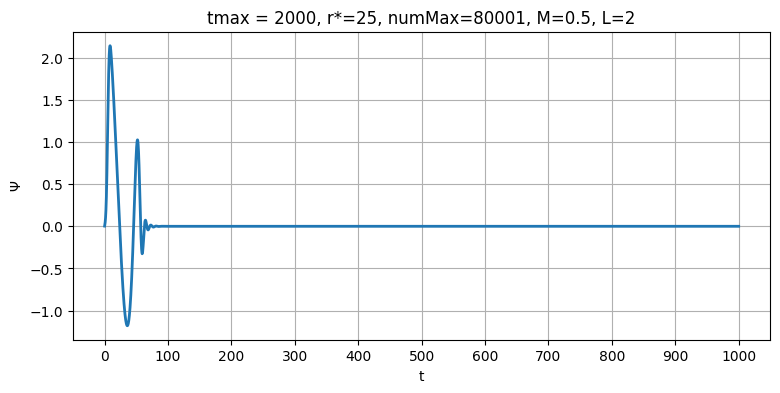

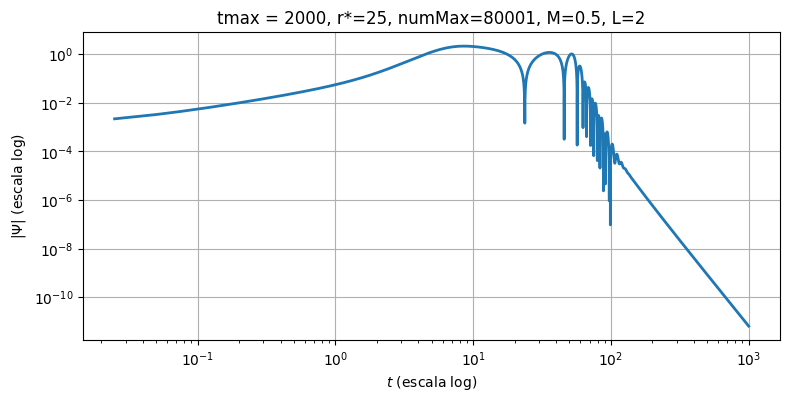

In [162]:
# def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
test1 = getEvo(tmax, rsv, numMax, M, L, pertubation_params)
title_str = f"tmax = {tmax}, r*={rsv}, numMax={numMax}, M={M}, L={L}"
plotEvolution(
    test1,
    title_str
)
plotLogEvolution(
    test1,
    title_str
)

In [163]:
def plotLogEvolutionmod(test, title=""):

    ht, psi = test
    # print(f"len(psi): {len(psi)}")
    # print(f"ht: {ht}")

    t = ht * np.arange(3000, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi[2999:]),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)


    plt.show()

In [164]:
ht, psi = test1
# Tempo correspondente
t = ht * np.arange(1, len(psi) + 1)

# Intervalo desejado
t_inicio_temp = 300.0
t_final_temp = 900.0

t_inicial = int(round(t_inicio_temp / ht))
t_final = int(round(t_final_temp / ht))

t_fit = t[t_inicial:t_final]
psi_fit = np.abs(psi[t_inicial:t_final])

# Evita log(0)
mask = psi_fit > 0

x = np.log(t_fit[mask])
y = np.log(psi_fit[mask])

# Ajuste linear
coef = np.polyfit(x, y, 1)

slope = coef[0]
intercept = coef[1]

print(f"Inclinação = {slope:.6f}")
print(f"Intercepto = {intercept:.6f}")

Inclinação = -7.049696
Intercepto = 22.953645


Default Return (full=False, cov=False)When you run the default configuration, it only returns the coefficients array (p).Shape: (deg + 1,) where deg is the polynomial degree you requested.Order: Highest degree term to lowest degree term (\(c_n, c_{n-1}, ..., c_0\)).Example: Fitting a line (y = mx + b) using deg=1 returns [m, b].

If a static I,-pole field is present outside the star, prior to the onset of collapse,
the field will fall off as t
'"'". If there is no field
initially outside the star, but an l-pole perturbation develops during the collapse process, it will
fall off as t^(2l+3) a.t la.rge time

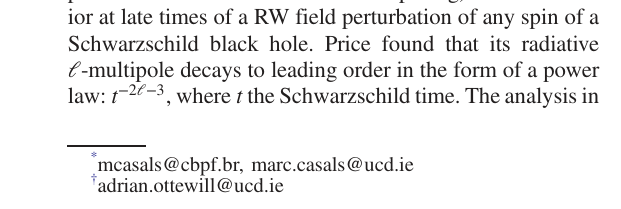

10.1103/PhysRevD.92.124055

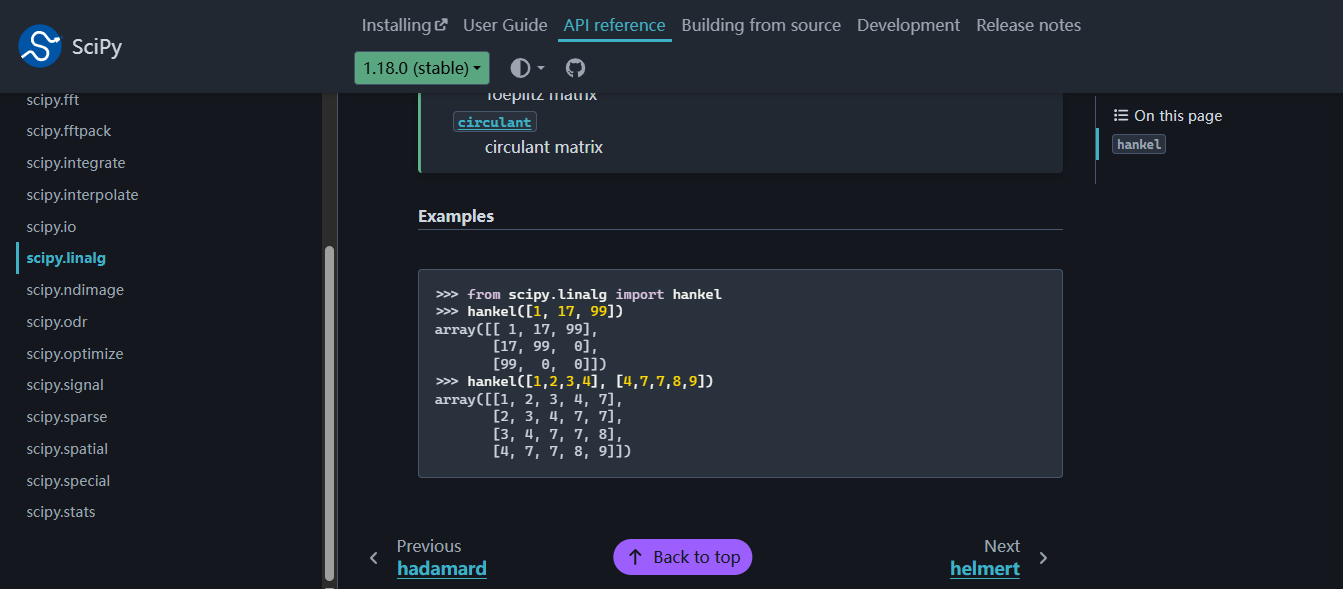

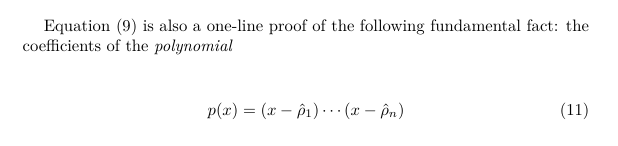

In [165]:
# pronyi = 0
# pronyf = len(psi)-1
# #len(psi) = 10000
# print(f"A seção selecionado para análise de Prony é de {pronyi} a {pronyf}")
# ht, psi = test1
# range_array = psi[pronyi:pronyf]
# n = 6


# num_colunas_total = n + 1  # 6 colunas para A + 1 coluna para o vetor b (total = 7)
# num_linhas = len(range_array) - num_colunas_total + 1  # 500 - 7 + 1 = 494 linhas

# # 3. Construir a Matriz de Hankel deslizante correta
# # Primeira coluna: os primeiros num_linhas pontos
# # Última linha: os últimos num_colunas_total pontos
# c = range_array[:num_linhas]
# r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #(494-1 : 494-1+7) = 493:500

# matriz_hankel_completa = hankel(c, r)

# # 4. Separar em Matriz A (300x6) e Vetor b (300x1)
# # Se quiser limitar estritamente a 300 linhas:
# # matriz_hankel_completa = matriz_hankel_completa[:300, :]

# matriz_A = matriz_hankel_completa[:, :n]  # Colunas de Psi_0 até Psi_5 (300x6)
# vetor_b = -matriz_hankel_completa[:, n]  # Coluna Psi_6 com sinal trocado (300x1)
# # print(f"vetor_b: {vetor_b}")
# print(f"matriz_a.shape: {matriz_A.shape}, vetor_b.shape: {vetor_b.shape}")

# p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
#     matriz_A, vetor_b, rcond=None
# )

# # 5. Salvar a Matriz A e o Vetor b em uma planilha do Excel
# # Criamos um DataFrame do pandas organizando as colunas
# # colunas_nomes = [f"Psi_k+{i}" for i in range(n)] + ["-Psi_k+6 (vetor_b)"]
# # df_excel = pd.DataFrame(matriz_hankel_completa, columns=colunas_nomes)

# # # Salva no arquivo Excel
# # nome_arquivo = "matriz_hankel_prony.xlsx"
# # df_excel.to_csv(nome_arquivo, index=False)

# # print(f"Matriz de Hankel criada com sucesso! Formato: {matriz_hankel_completa.shape}")
# # print(f"Arquivo salvo como: '{nome_arquivo}'")

# #==========================================================================================
# # 1. Agrupar todos os coeficientes em ordem DECRESCENTE de potência
# # p_coef vem do lstsq: [p0, p1, p2, p3, p4, p5]
# # O termo de maior grau p6 é igual a 1.0
# coefs_polinomio = [1.0] + list(p_coef[::-1])

# # 2. Encontrar os rhos (\hat{\rho}_j) calculando as raízes do polinômio
# rhos = np.roots(coefs_polinomio)

# # print("Os 'rhos' (raízes complexas) encontrados são:")
# # print(rhos)

# dt = ht

# # Converter os 'rhos' para as frequências físicas omegas
# omegas = 1j * np.log(rhos) / dt

# # Exibir os resultados
# for j, w in enumerate(omegas):
#     print(
#         f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}"
#     )

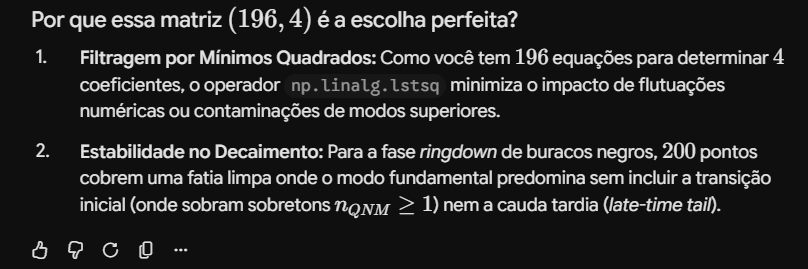

In [166]:
# # n =0 (overtone) — janela definida em TEMPO FÍSICO, não em número de amostras fixo

# ht, psi = test1
# # 2*pi / 0.34671 = 18.1

# # --- Parâmetros físicos da janela (o que muda de verdade) ---
# t_inicio_janela = 5.0        # pula o transiente inicial antes da ringdown se estabelecer
# duracao_janela = 30.0        # ~1.5-2 períodos do overtone n=1 (T ≈ 18.1)
# n = 10                        # ordem do polinômio de Prony

# # --- Conversão para índices, usando o ht ATUAL (funciona igual para qualquer numMax) ---
# pronyi = int(round(t_inicio_janela / ht))
# pronyf = int(round((t_inicio_janela + duracao_janela) / ht))

# passo = 1
# i = 0
# itotal = (len(psi) - pronyf) / passo
# nome_arquivo = "resultados_prony_n0_passo1.txt"

# with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
#     while True:
#         pronyireal = pronyi + i * passo
#         pronyfreal = pronyf + i * passo
#         range_array = psi[pronyireal:pronyfreal]

#         t_ini_real = pronyireal * ht
#         t_fim_real = pronyfreal * ht

#         arquivo.write(f"\n")
#         arquivo.write(
#             f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal} "
#             f"(t = {t_ini_real:.3f} a {t_fim_real:.3f})\n"
#         )

#         num_colunas_total = n + 1
#         num_linhas = len(range_array) - num_colunas_total + 1

#         c = range_array[:num_linhas]
#         r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

#         matriz_hankel_completa = hankel(c, r)

#         matriz_A = matriz_hankel_completa[:, :n]
#         vetor_b = -matriz_hankel_completa[:, n]

#         p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
#             matriz_A, vetor_b, rcond=None
#         )

#         # --- Diagnóstico de condicionamento (novo) ---
#         cond_number = valores_singulares[0] / valores_singulares[-1]
#         arquivo.write(f"Número de condição da matriz A: {cond_number:.3e}\n")

#         coefs_polinomio = [1.0] + list(p_coef[::-1])
#         rhos = np.roots(coefs_polinomio)

#         dt = ht
#         omegas = 1j * np.log(rhos) / dt

#         for j, w in enumerate(omegas):
#             arquivo.write(
#                 f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}\n"
#             )
#         i += 1
#         if i > itotal:
#             break

# print(f"Janela usada: pronyi={pronyi}, pronyf={pronyf} "
#       f"(t = {pronyi*ht:.3f} a {pronyf*ht:.3f}), ht={ht}")

In [167]:
# # n = 0
# ht, psi = test1
# t_inicio_janela = 0.0
# duracao_janela = 15.0
# t_limite_busca = 400.0
# passo = 1
# i = 0
# n = 4

# pronyi = int(round(t_inicio_janela / ht))
# pronyf = int(round((t_inicio_janela + duracao_janela) / ht))

# pronyi_max = int(round(t_limite_busca / ht))
# itotal = (pronyi_max - pronyi) / passo
# nome_arquivo = "resultados_prony_n0_passo1.txt"
# with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
#     while True:
#         pronyireal = pronyi + i * passo
#         pronyfreal = pronyf + i * passo
#         range_array = psi[pronyireal:pronyfreal]

#         t_ini_real = pronyireal * ht
#         t_fim_real = pronyfreal * ht

#         arquivo.write(f"\n")
#         arquivo.write(
#             f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal} "
#             f"(t = {t_ini_real:.3f} a {t_fim_real:.3f})\n"
#         )

#         num_colunas_total = n + 1
#         num_linhas = len(range_array) - num_colunas_total + 1

#         c = range_array[:num_linhas]
#         r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

#         matriz_hankel_completa = hankel(c, r)

#         matriz_A = matriz_hankel_completa[:, :n]
#         vetor_b = -matriz_hankel_completa[:, n]

#         p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
#             matriz_A, vetor_b, rcond=None
#         )

#         # --- Diagnóstico de condicionamento (novo) ---
#         cond_number = valores_singulares[0] / valores_singulares[-1]
#         arquivo.write(f"Número de condição da matriz A: {cond_number:.3e}\n")

#         coefs_polinomio = [1.0] + list(p_coef[::-1])
#         rhos = np.roots(coefs_polinomio)

#         dt = ht
#         omegas = 1j * np.log(rhos) / dt

#         for j, w in enumerate(omegas):
#             arquivo.write(
#                 f"Modo {j+1}: omega_R = {w.real:.10f} | omega_I = {-w.imag:.10f}\n"
#             )
#         i += 1
#         if i > itotal:
#             break

# print(f"Janela usada: pronyi={pronyi}, pronyf={pronyf} "
#       f"(t = {pronyi*ht:.3f} a {pronyf*ht:.3f}), ht={ht}")

In [168]:
# --- Configurações e Alvos Teóricos ---
ht, psi = test1
omega_R_teorico, omega_I_teorico = n0

t_inicio_janela = 60.0
t_limite_busca = 300.0
n = 4  # Ordem do polinômio de Prony
passo = 1

casas_decimais = 7  # Exige que os primeiros N dígitos decimais sejam idênticos ao teórico
fator_trunc = 10**casas_decimais

min_passos_consecutivos = 2  # Exige no mínimo N janelas seguidas sem quebra temporal

nome_arquivo_saida = "varredura_duracao_prony_n0_platôs_continuos.txt"
duracoes = np.arange(10.0, 30.1, 0.1)

tempo_inicio_global = time.time()

# --- NOVO: Variáveis para rastrear o máximo de modos ---
max_modos = -1
melhor_duracao = None

with open(nome_arquivo_saida, "w", encoding="utf-8") as arquivo_out:
    pbar = tqdm(duracoes, desc="Varredura Prony", unit="janela")

    for duracao_janela in pbar:
        pronyi = int(round(t_inicio_janela / ht))
        pronyf = int(round((t_inicio_janela + duracao_janela) / ht))
        pronyi_max = int(round(t_limite_busca / ht))
        itotal = pronyi_max - pronyi

        candidatos = []
        i = 0

        while i <= itotal:
            pronyireal = pronyi + i * passo
            pronyfreal = pronyf + i * passo
            range_array = psi[pronyireal:pronyfreal]

            num_colunas_total = n + 1
            num_linhas = len(range_array) - num_colunas_total + 1

            if num_linhas < 1 or len(range_array) < num_colunas_total:
                i += 1
                continue

            c = range_array[:num_linhas]
            r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

            matriz_hankel_completa = hankel(c, r)
            matriz_A = matriz_hankel_completa[:, :n]
            vetor_b = -matriz_hankel_completa[:, n]

            p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
                matriz_A, vetor_b, rcond=None
            )

            coefs_polinomio = [1.0] + list(p_coef[::-1])
            rhos = np.roots(coefs_polinomio)

            with np.errstate(invalid="ignore", divide="ignore"):
                omegas = 1j * np.log(rhos) / ht

            t_ini_real = pronyireal * ht
            t_fim_real = pronyfreal * ht
            secao_str = (
                f"Seção: {pronyireal} a {pronyfreal} "
                f"(t = {t_ini_real:.3f}M a {t_fim_real:.3f}M)"
            )

            for j, w in enumerate(omegas):
                if np.isnan(w) or np.isinf(w):
                    continue

                omega_R = w.real
                omega_I = -w.imag

                # Truncamento estrito nas N casas decimais
                trunc_R_calc = int(np.floor(abs(omega_R) * fator_trunc + 1e-9))
                trunc_R_teor = int(np.floor(omega_R_teorico * fator_trunc + 1e-9))

                trunc_I_calc = int(np.floor(omega_I * fator_trunc + 1e-9))
                trunc_I_teor = int(np.floor(omega_I_teorico * fator_trunc + 1e-9))

                if (trunc_R_calc == trunc_R_teor) and (trunc_I_calc == trunc_I_teor):
                    erro_abs_R = abs(abs(omega_R) - omega_R_teorico)
                    erro_abs_I = abs(omega_I - omega_I_teorico)
                    candidatos.append(
                        (
                            pronyireal,
                            secao_str,
                            j + 1,
                            omega_R,
                            omega_I,
                            erro_abs_R,
                            erro_abs_I,
                        )
                    )

            i += 1

        # --- FILTRO DE CONTINUIDADE TEMPORAL ---
        candidatos_continuos = []
        if candidatos:
            blocos = []
            bloco_atual = [candidatos[0]]

            for c in candidatos[1:]:
                idx_anterior = bloco_atual[-1][0]
                idx_atual = c[0]

                if idx_atual == idx_anterior or idx_atual == idx_anterior + passo:
                    bloco_atual.append(c)
                else:
                    passos_unicos = len(set(item[0] for item in bloco_atual))
                    if passos_unicos >= min_passos_consecutivos:
                        blocos.append(bloco_atual)
                    bloco_atual = [c]

            passos_unicos = len(set(item[0] for item in bloco_atual))
            if passos_unicos >= min_passos_consecutivos:
                blocos.append(bloco_atual)

            for b in blocos:
                candidatos_continuos.extend(b)

        # --- NOVO: Atualiza o recorde do número de modos ---
        num_modos_atual = len(candidatos_continuos)
        if num_modos_atual > max_modos:
            max_modos = num_modos_atual
            melhor_duracao = duracao_janela

        pbar.set_postfix(
            {"dur": f"{duracao_janela:.1f}M", "aprovados": len(candidatos_continuos)}
        )

        # --- GRAVAÇÃO DOS RESULTADOS ---
        arquivo_out.write("=" * 75 + "\n")
        arquivo_out.write(
            f"DURAÇÃO DA JANELA: {duracao_janela:.1f} M | PLATÔS CONTÍNUOS: {len(candidatos_continuos)} MODOS\n"
        )
        arquivo_out.write("=" * 75 + "\n")

        if not candidatos_continuos:
            arquivo_out.write(
                "Nenhum platô contínuo encontrado para esta duração.\n\n"
            )
        else:
            for idx, secao, modo, wr, wi, err_r, err_i in candidatos_continuos:
                arquivo_out.write(f"{secao}\n")
                arquivo_out.write(
                    f"  Modo {modo}: omega_R = {wr:.10f} | omega_I = {wi:.10f} "
                    f"(erro_abs_R = {err_r:.3e}, erro_abs_I = {err_i:.3e})\n\n"
                )

tempo_total = time.time() - tempo_inicio_global
print(f"\n=== VARREDURA CONCLUÍDA ===")
print(f"Tempo total de execução: {tempo_total / 60:.2f} minutos.")
# --- NOVO: Print final com o maior resultado encontrado ---
print(f"Maior número de modos filtrados: {max_modos} (na duração: {melhor_duracao:.1f} M)")

Varredura Prony: 100%|██████████| 201/201 [13:35<00:00,  4.06s/janela, dur=30.0M, aprovados=0]


=== VARREDURA CONCLUÍDA ===
Tempo total de execução: 13.59 minutos.
Maior número de modos filtrados: 0 (na duração: 10.0 M)
